# UMAMI Urban Heat V2.1 — Multi-Task Training

**Goal:** drop V2's RMSE from 4.77 °C toward 3.2 °C and fix the d306_h13 catastrophe (16.3 °C error).

**Approach:** keep V2's ResNet34-UNet backbone, but:
1. Add a 12th input channel: ERA5 Tair (broadcast scalar) — gives the model an absolute temperature anchor
2. Add 2 extra prediction heads: LST + sparse sensor Tair — multi-task supervision
3. Replace channels 0 (DSM) and 2 (albedo) with cleaner Geoscape-derived versions
4. Warm-start from V2 best.pt (extend first conv to 12 channels, zero-init slot 11)

**Inputs (on Drive at `gdrive:UMAMI/urban_heat_v3/`):**
- `patches_v21.tar` — single 30 GB tar containing 11,844 .npz + manifest.parquet (extracted to `/content/patches_v21/` in cell 1.5 below for fast random-access training; Drive mount is too slow for tens of thousands of small reads)
- `models/best_model_v2.pt` — V2 checkpoint for warm-start

**Output:** `gdrive:UMAMI/urban_heat_v3/models/v21_best.pt` + `umami_unet_v21_fp32.onnx`

**Runtime:** ~3-4 h on a single A100; works on T4 with smaller BS but slower.

## 1 — Setup (Drive mount + dependencies)

In [26]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### 1.5 — Extract patches_v21.tar from Drive to local /content

Drive mount is fine for the 30 GB single-file copy (saturates ~50-100 MB/s on Colab) but terrible for the per-iteration random-access reads of 8,440 .npz files during training. We copy + extract once at the start so DataLoader hits Colab's local SSD instead.

This step takes ~5-10 minutes the first time; subsequent restarts of the same Colab VM skip it (the `if Path('/content/patches_v21').exists()` guard).

In [27]:
import time, shutil
from pathlib import Path

DRIVE_TAR = Path('/content/drive/MyDrive/UMAMI/urban_heat_v3/patches_v21.tar')
LOCAL_TAR = Path('/content/patches_v21.tar')
LOCAL_PATCHES = Path('/content/patches_v21')

if LOCAL_PATCHES.exists() and any(LOCAL_PATCHES.glob('*.npz')):
    n = len(list(LOCAL_PATCHES.glob('*.npz')))
    print(f'patches already extracted at {LOCAL_PATCHES} ({n:,} files) — skipping')
else:
    if not DRIVE_TAR.exists():
        raise FileNotFoundError(f'expected {DRIVE_TAR} on Drive — did the upload from the server complete?')

    if not LOCAL_TAR.exists():
        t0 = time.time()
        print(f'copying {DRIVE_TAR.name} → /content/ ({DRIVE_TAR.stat().st_size / 1e9:.1f} GB) …')
        shutil.copyfile(DRIVE_TAR, LOCAL_TAR)
        print(f'  copy done in {time.time()-t0:.0f}s')
    else:
        print(f'using existing {LOCAL_TAR}')

    t0 = time.time()
    print(f'extracting {LOCAL_TAR} → /content/ …')
    !tar -xf {LOCAL_TAR} -C /content/
    print(f'  extract done in {time.time()-t0:.0f}s')
    n = len(list(LOCAL_PATCHES.glob('*.npz')))
    print(f'  {n:,} .npz files in {LOCAL_PATCHES}')

    # Free disk: the tar is ~30 GB and we don't need it after extraction
    LOCAL_TAR.unlink(missing_ok=True)
    print(f'  removed local tar to free disk')

patches already extracted at /content/patches_v21 (11,844 files) — skipping


In [28]:
# Drive paths (adjust if your Drive layout differs)
DRIVE_ROOT = Path('/content/drive/MyDrive/UMAMI/urban_heat_v3')

# Patches were extracted to local /content in cell 1.5 above (Drive mount is too
# slow for tens of thousands of small reads during training).
PATCHES_DIR = Path('/content/patches_v21')
MANIFEST_PATH = PATCHES_DIR / 'manifest.parquet'

V2_CKPT_PATH = DRIVE_ROOT / 'models' / 'best_model_v2.pt'
OUT_DIR = DRIVE_ROOT / 'models'
OUT_DIR.mkdir(parents=True, exist_ok=True)

# V2.1 channel order — must match patch_builder.CHANNEL_ORDER
CHANNEL_ORDER = (
    'dsm_corrected', 'cdsm', 'albedo',
    'sin_alt', 'alt_norm',
    'svf', 'building_density', 'tree_distance',
    'aspect_sin', 'aspect_cos', 'shadow_fraction',
    'era5_tair_c',
)
NUM_CHANNELS = len(CHANNEL_ORDER)
assert NUM_CHANNELS == 12

# Three multi-task heads — order is fixed and used by the loss
HEAD_NAMES = ('tmrt', 'lst', 'tair_sparse')
NUM_HEADS = len(HEAD_NAMES)

# Per-head loss weights — sensor signal is rare, so it gets upweighted
LOSS_WEIGHTS = {'tmrt': 1.0, 'lst': 0.5, 'tair_sparse': 10.0}

In [29]:
import os
import json
import time
import math
from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import segmentation_models_pytorch as smp
import matplotlib.pyplot as plt

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'device={DEVICE}, cuda_name={torch.cuda.get_device_name() if DEVICE.type == "cuda" else "-"}')

device=cuda, cuda_name=NVIDIA A100-SXM4-80GB


## 2 — Data loading

In [30]:
manifest = pd.read_parquet(MANIFEST_PATH)
print(f'manifest rows: {len(manifest):,}')
print(f'unique V2 patches: {manifest["v2_patch_id"].nunique()}')
print(f'unique temporal combos: {manifest[["doy", "hour"]].drop_duplicates().shape[0]}')
print()
print(f'has_tmrt        : {int(manifest["has_tmrt"].sum())} / {len(manifest)}')
print(f'has_lst         : {int(manifest["has_lst"].sum())} / {len(manifest)}')
print(f'num_sensors > 0 : {int((manifest["num_sensors_in_patch"] > 0).sum())} / {len(manifest)}')
print()
# Drop rows without T_mrt — those are useless for V2.1's primary signal
manifest = manifest[manifest['has_tmrt']].reset_index(drop=True)
print(f'after dropping has_tmrt=False: {len(manifest):,} rows')

manifest rows: 11,844
unique V2 patches: 987
unique temporal combos: 12

has_tmrt        : 11844 / 11844
has_lst         : 0 / 11844
num_sensors > 0 : 0 / 11844

after dropping has_tmrt=False: 11,844 rows


In [31]:
# Train/val/test split — by V2 patch_id so the same geographic location
# never appears in both train and test. Hold out d306_h13 examples
# explicitly in test to verify the catastrophic combo is fixed.
rng = np.random.default_rng(seed=42)
all_v2_ids = manifest['v2_patch_id'].unique()
rng.shuffle(all_v2_ids)
n_test = int(len(all_v2_ids) * 0.10)
n_val = int(len(all_v2_ids) * 0.10)
test_ids = set(all_v2_ids[:n_test])
val_ids = set(all_v2_ids[n_test:n_test + n_val])
train_ids = set(all_v2_ids[n_test + n_val:])

manifest['split'] = manifest['v2_patch_id'].apply(
    lambda pid: 'train' if pid in train_ids else 'val' if pid in val_ids else 'test'
)
print(manifest['split'].value_counts())
print()
print('d306_h13 distribution:')
print(manifest[(manifest['doy'] == 306) & (manifest['hour'] == 13)]['split'].value_counts())

split
train    9492
test     1176
val      1176
Name: count, dtype: int64

d306_h13 distribution:
split
train    791
test      98
val       98
Name: count, dtype: int64


In [32]:
class V21PatchDataset(Dataset):
    """Loads (input_12ch, tmrt, lst, tair_sparse) from .npz files.

    Labels arrive with NaN cells where supervision is missing.
    The training loop's loss handles those.
    """
    def __init__(self, manifest_df: pd.DataFrame, patches_dir: Path):
        self.df = manifest_df.reset_index(drop=True)
        self.patches_dir = Path(patches_dir)
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        npz_path = self.patches_dir / Path(row['npz_path']).name
        with np.load(npz_path) as data:
            inp = data['input'].astype(np.float32)        # (12, H, W)
            tmrt = data['tmrt'].astype(np.float32)        # (H, W)
            lst = data['lst'].astype(np.float32)          # (H, W)
            tair = data['tair_sparse'].astype(np.float32) # (H, W)
        return {
            'input': torch.from_numpy(inp),
            'tmrt': torch.from_numpy(tmrt),
            'lst': torch.from_numpy(lst),
            'tair_sparse': torch.from_numpy(tair),
            'patch_id': row['patch_id'],
            'doy': int(row['doy']),
            'hour': int(row['hour']),
        }

train_ds = V21PatchDataset(manifest[manifest['split'] == 'train'], PATCHES_DIR)
val_ds = V21PatchDataset(manifest[manifest['split'] == 'val'], PATCHES_DIR)
test_ds = V21PatchDataset(manifest[manifest['split'] == 'test'], PATCHES_DIR)
print(f'train={len(train_ds)}, val={len(val_ds)}, test={len(test_ds)}')

# Quick sanity check on shapes
sample = train_ds[0]
for k, v in sample.items():
    if torch.is_tensor(v):
        print(f'  {k}: shape={tuple(v.shape)}, dtype={v.dtype}')
    else:
        print(f'  {k}: {v}')

train=9492, val=1176, test=1176
  input: shape=(12, 512, 512), dtype=torch.float32
  tmrt: shape=(512, 512), dtype=torch.float32
  lst: shape=(512, 512), dtype=torch.float32
  tair_sparse: shape=(512, 512), dtype=torch.float32
  patch_id: patch_0007_d015_h09
  doy: 15
  hour: 9


In [33]:
BATCH_SIZE = 16
NUM_WORKERS = 4

train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=True, drop_last=True,
)
val_loader = DataLoader(
    val_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True,
)
test_loader = DataLoader(
    test_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True,
)

## 3 — Model: ResNet34-UNet with 3 multi-task heads + warm-start

In [34]:
# Warm-start from V2 best.pt — extend first conv to 12 channels,
# zero-init slot 11 (ERA5) so V2 behaviour is preserved at epoch 0
if V2_CKPT_PATH.exists():
    print(f'warm-starting from {V2_CKPT_PATH}')
    raw = torch.load(V2_CKPT_PATH, map_location='cpu')
    # V2 wraps weights under 'model'; other checkpoints use 'state_dict' or are flat.
    if isinstance(raw, dict) and 'model' in raw and isinstance(raw['model'], dict):
        v2_state = raw['model']
        print(f"  unwrapped from 'model' key (V2 epoch={raw.get('epoch','?')}, "
              f"val_rmse={raw.get('best_val_rmse', float('nan')):.3f})")
    elif isinstance(raw, dict) and 'state_dict' in raw:
        v2_state = raw['state_dict']
    else:
        v2_state = raw

    # First conv: V2 was 11 in-channels; V2.1 is 12. Extend along dim 1.
    v2_first_conv = v2_state.get('encoder.conv1.weight')
    if v2_first_conv is not None:
        n_out, n_in_v2, k1, k2 = v2_first_conv.shape
        if n_in_v2 == 11:
            new_conv = torch.zeros(n_out, NUM_CHANNELS, k1, k2)
            new_conv[:, :11] = v2_first_conv
            new_conv[:, 11] = 0.0  # ERA5 channel — start neutral
            v2_state['encoder.conv1.weight'] = new_conv
            print(f'  extended encoder.conv1 from (11) to (12) input channels')
    else:
        print('  WARNING: encoder.conv1.weight not found — first-conv extension skipped')

    # Final segmentation head: V2 had classes=1, V2.1 has classes=3 — drop
    # the V2 head weights (if any) so SMP's random-init is used
    drop = [k for k in v2_state if k.startswith('segmentation_head')]
    for k in drop:
        del v2_state[k]
    print(f'  dropped {len(drop)} segmentation_head keys (incompatible shapes)')

    missing, unexpected = model.load_state_dict(v2_state, strict=False)
    print(f'  loaded; missing={len(missing)}, unexpected={len(unexpected)}')
    if len(missing) <= 5:
        print(f'  missing keys: {missing}')
    if 0 < len(unexpected) <= 5:
        print(f'  unexpected keys: {unexpected}')
else:
    print(f'V2 checkpoint not found at {V2_CKPT_PATH} — training from scratch')

model = model.to(DEVICE)

warm-starting from /content/drive/MyDrive/UMAMI/urban_heat_v3/models/best_model_v2.pt
  unwrapped from 'model' key (V2 epoch=11, val_rmse=4.751)
  extended encoder.conv1 from (11) to (12) input channels
  dropped 0 segmentation_head keys (incompatible shapes)
  loaded; missing=124, unexpected=39


In [35]:
# Warm-start from V2 best.pt — extend first conv to 12 channels,
# zero-init slot 11 (ERA5) so V2 behaviour is preserved at epoch 0
if V2_CKPT_PATH.exists():
    print(f'warm-starting from {V2_CKPT_PATH}')
    v2_state = torch.load(V2_CKPT_PATH, map_location='cpu')
    if 'state_dict' in v2_state:
        v2_state = v2_state['state_dict']

    # First conv: V2 was 11 in-channels; V2.1 is 12. Extend along dim 1.
    v2_first_conv = v2_state.get('encoder.conv1.weight')
    if v2_first_conv is not None:
        n_out, n_in_v2, k1, k2 = v2_first_conv.shape
        if n_in_v2 == 11:
            new_conv = torch.zeros(n_out, NUM_CHANNELS, k1, k2)
            new_conv[:, :11] = v2_first_conv
            new_conv[:, 11] = 0.0  # ERA5 channel — start neutral
            v2_state['encoder.conv1.weight'] = new_conv
            print(f'  extended encoder.conv1 from (11) to (12) input channels')

    # Final segmentation head: V2 had classes=1, V2.1 has classes=3 — drop
    # the V2 head weights so SMP's random-init is used
    drop = [k for k in v2_state if k.startswith('segmentation_head')]
    for k in drop:
        del v2_state[k]
    print(f'  dropped {len(drop)} segmentation_head keys (incompatible shapes)')

    missing, unexpected = model.load_state_dict(v2_state, strict=False)
    print(f'  loaded; missing={len(missing)}, unexpected={len(unexpected)}')
else:
    print(f'V2 checkpoint not found at {V2_CKPT_PATH} — training from scratch')

model = model.to(DEVICE)

warm-starting from /content/drive/MyDrive/UMAMI/urban_heat_v3/models/best_model_v2.pt
  dropped 0 segmentation_head keys (incompatible shapes)
  loaded; missing=232, unexpected=7


In [36]:
# Sanity-check: did V2's encoder weights actually land?
v2_first = raw['model']['encoder.conv1.weight']
model_first = model.encoder.conv1.weight.data.cpu()
print(f"V2 first conv first 11 channels mean abs : {v2_first.abs().mean().item():.4f}")
print(f"Model first 11 channels mean abs        : {model_first[:, :11].abs().mean().item():.4f}")
print(f"Model channel 11 (ERA5 — should be ~0)  : {model_first[:, 11].abs().mean().item():.4e}")
print(f"Match V2 ↔ model on channels 0-10       : "
      f"{(v2_first - model_first[:, :11].cpu()).abs().max().item():.2e}  "
      f"(should be 0 if warm-start worked)")

# Spot-check a layer1 weight
v2_l1 = raw['model'].get('encoder.layer1.0.conv1.weight')
m_l1 = model.encoder.layer1[0].conv1.weight.data.cpu()
if v2_l1 is not None:
    print(f"layer1.0.conv1 match: {(v2_l1 - m_l1).abs().max().item():.2e}")

V2 first conv first 11 channels mean abs : 0.0294
Model first 11 channels mean abs        : 0.0320
Model channel 11 (ERA5 — should be ~0)  : 0.0000e+00


RuntimeError: The size of tensor a (12) must match the size of tensor b (11) at non-singleton dimension 1

In [37]:
import torch
raw_fresh = torch.load(V2_CKPT_PATH, map_location='cpu')
v2_orig = raw_fresh['model']['encoder.conv1.weight']  # original (64, 11, 7, 7)
m = model.encoder.conv1.weight.data.cpu()               # current (64, 12, 7, 7)

print(f"V2 conv1 shape   : {tuple(v2_orig.shape)}")
print(f"Model conv1 shape: {tuple(m.shape)}")
print(f"max |V2 - model[:, :11]|  : {(v2_orig - m[:, :11]).abs().max().item():.2e}  (should be 0)")
print(f"model channel 11 max abs  : {m[:, 11].abs().max().item():.2e}  (should be 0)")

# Spot-check a deep encoder layer
v2_l4 = raw_fresh['model'].get('encoder.layer4.0.conv1.weight')
m_l4 = model.encoder.layer4[0].conv1.weight.data.cpu()
if v2_l4 is not None:
    print(f"max |V2 - model| layer4.0.conv1: {(v2_l4 - m_l4).abs().max().item():.2e}")

V2 conv1 shape   : (64, 11, 7, 7)
Model conv1 shape: (64, 12, 7, 7)
max |V2 - model[:, :11]|  : 0.00e+00  (should be 0)
model channel 11 max abs  : 0.00e+00  (should be 0)
max |V2 - model| layer4.0.conv1: 0.00e+00


## 4 — Multi-task NaN-aware loss

Each label channel may have NaN cells (no supervision). MSE is computed only over finite cells.

If a head has zero finite cells in a batch, that head's contribution is 0 (no gradient through that branch for this batch). This lets sparse signals (sensor Tair: ~1 finite cell per patch) coexist with dense signals (T_mrt: ~95% finite cells per patch) in one training loop.

In [38]:
def masked_mse(pred: torch.Tensor, target: torch.Tensor) -> torch.Tensor:
    mask = torch.isfinite(target)
    if mask.sum() == 0:
        return torch.tensor(0.0, device=pred.device, requires_grad=True)
    diff = pred[mask] - target[mask]
    return (diff ** 2).mean()

def multi_task_loss(pred_3ch: torch.Tensor, batch: dict) -> tuple[torch.Tensor, dict]:
    """pred_3ch: (B, 3, H, W) — channels in HEAD_NAMES order."""
    losses = {}
    for i, head in enumerate(HEAD_NAMES):
        target = batch[head].to(pred_3ch.device, non_blocking=True)
        losses[head] = masked_mse(pred_3ch[:, i], target)
    total = sum(LOSS_WEIGHTS[h] * losses[h] for h in HEAD_NAMES)
    return total, losses

## 5 — Training loop

In [39]:
EPOCHS = 100
LR = 1e-4
WEIGHT_DECAY = 1e-5
GRAD_CLIP = 5.0

opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)

history = {'train_loss': [], 'val_loss': [],
           'val_rmse_tmrt': [], 'val_rmse_lst': [], 'val_rmse_tair': []}
best_val_rmse_tmrt = float('inf')
BEST_CKPT_PATH = OUT_DIR / 'v21_best.pt'

In [40]:
def epoch_pass(loader, training: bool) -> dict:
    """One pass over a loader. Returns per-head total SE and pixel counts."""
    model.train(training)  # True for train, False for inference
    accum_loss = 0.0
    se = {h: 0.0 for h in HEAD_NAMES}
    n  = {h: 0 for h in HEAD_NAMES}
    n_batches = 0
    ctx = torch.enable_grad() if training else torch.no_grad()
    with ctx:
        for batch in loader:
            x = batch['input'].to(DEVICE, non_blocking=True)
            pred = model(x)  # (B, 3, H, W)
            total, losses = multi_task_loss(pred, batch)
            if training:
                opt.zero_grad()
                total.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
                opt.step()
            accum_loss += float(total.detach().cpu())
            n_batches += 1
            # Accumulate squared error per head for proper RMSE
            for i, h in enumerate(HEAD_NAMES):
                tgt = batch[h].to(DEVICE, non_blocking=True)
                mask = torch.isfinite(tgt)
                if mask.sum() > 0:
                    diff = pred[:, i][mask] - tgt[mask]
                    se[h] += float((diff ** 2).sum().detach().cpu())
                    n[h] += int(mask.sum().detach().cpu())
    rmse = {h: math.sqrt(se[h] / max(n[h], 1)) if n[h] > 0 else float('nan') for h in HEAD_NAMES}
    return {'loss': accum_loss / max(n_batches, 1), 'rmse': rmse, 'pixel_counts': n}

In [41]:
for epoch in range(EPOCHS):
    t0 = time.time()
    train_stats = epoch_pass(train_loader, training=True)
    val_stats = epoch_pass(val_loader, training=False)
    scheduler.step()

    history['train_loss'].append(train_stats['loss'])
    history['val_loss'].append(val_stats['loss'])
    history['val_rmse_tmrt'].append(val_stats['rmse']['tmrt'])
    history['val_rmse_lst'].append(val_stats['rmse']['lst'])
    history['val_rmse_tair'].append(val_stats['rmse']['tair_sparse'])

    elapsed = time.time() - t0
    print(
        f'epoch {epoch+1:3d}/{EPOCHS}  '
        f'train={train_stats["loss"]:.3f}  val={val_stats["loss"]:.3f}  '
        f'rmse[tmrt={val_stats["rmse"]["tmrt"]:.3f} '
        f'lst={val_stats["rmse"]["lst"]:.3f} '
        f'tair={val_stats["rmse"]["tair_sparse"]:.3f}]  '
        f'lr={scheduler.get_last_lr()[0]:.2e}  '
        f'{elapsed:.0f}s'
    )

    if val_stats['rmse']['tmrt'] < best_val_rmse_tmrt:
        best_val_rmse_tmrt = val_stats['rmse']['tmrt']
        torch.save({
            'epoch': epoch,
            'state_dict': model.state_dict(),
            'val_rmse_tmrt': best_val_rmse_tmrt,
            'history': history,
        }, BEST_CKPT_PATH)
        print(f'  ↳ best so far ({best_val_rmse_tmrt:.3f} °C); checkpointed')

epoch   1/100  train=589.993  val=477.497  rmse[tmrt=21.804 lst=nan tair=nan]  lr=1.00e-04  199s
  ↳ best so far (21.804 °C); checkpointed
epoch   2/100  train=416.449  val=289.696  rmse[tmrt=16.964 lst=nan tair=nan]  lr=9.99e-05  198s
  ↳ best so far (16.964 °C); checkpointed
epoch   3/100  train=260.257  val=186.038  rmse[tmrt=13.523 lst=nan tair=nan]  lr=9.98e-05  198s
  ↳ best so far (13.523 °C); checkpointed
epoch   4/100  train=127.450  val=78.721  rmse[tmrt=8.755 lst=nan tair=nan]  lr=9.96e-05  197s
  ↳ best so far (8.755 °C); checkpointed
epoch   5/100  train=51.719  val=31.534  rmse[tmrt=5.641 lst=nan tair=nan]  lr=9.94e-05  196s
  ↳ best so far (5.641 °C); checkpointed
epoch   6/100  train=29.729  val=26.403  rmse[tmrt=5.143 lst=nan tair=nan]  lr=9.91e-05  196s
  ↳ best so far (5.143 °C); checkpointed
epoch   7/100  train=26.757  val=23.318  rmse[tmrt=4.869 lst=nan tair=nan]  lr=9.88e-05  197s
  ↳ best so far (4.869 °C); checkpointed
epoch   8/100  train=26.603  val=23.364  r

## 6 — Evaluation on test set + per-temporal-combo breakdown

**Success criteria** (from `EVALUATION.md` / `IMPLEMENTATION_PLAN.md`):
- RMSE vs SOLWEIG ≤ **3.2 °C** on held-out test set (V2: 4.77 °C)
- d306_h13 RMSE ≤ **1.0 °C** (V2: 16.3 °C — the catastrophe)
- RMSE vs Landsat LST ≤ **3.5 °C**
- RMSE vs sensor Tair ≤ **2.5 °C**

In [42]:
# Reload best checkpoint
ckpt = torch.load(BEST_CKPT_PATH, map_location=DEVICE)
model.load_state_dict(ckpt['state_dict'])
model.train(False)
print(f'loaded best (epoch {ckpt["epoch"]+1}, val_rmse_tmrt={ckpt["val_rmse_tmrt"]:.3f})')

test_stats = epoch_pass(test_loader, training=False)
print()
print('=== test-set results ===')
for h in HEAD_NAMES:
    target = {'tmrt': 3.2, 'lst': 3.5, 'tair_sparse': 2.5}[h]
    rmse = test_stats['rmse'][h]
    px = test_stats['pixel_counts'][h]
    status = 'PASS' if rmse <= target else 'FAIL'
    print(f'  {h:14s}: RMSE={rmse:.3f} °C  (target ≤ {target}) {status}  [{px:,} px]')

loaded best (epoch 81, val_rmse_tmrt=2.968)

=== test-set results ===
  tmrt          : RMSE=2.723 °C  (target ≤ 3.2) PASS  [277,337,964 px]
  lst           : RMSE=nan °C  (target ≤ 3.5) FAIL  [0 px]
  tair_sparse   : RMSE=nan °C  (target ≤ 2.5) FAIL  [0 px]


In [43]:
# Per-temporal-combo error breakdown — verify d306_h13 is fixed
test_df = manifest[manifest['split'] == 'test'].copy()
combo_se = {}
combo_n = {}
with torch.no_grad():
    for batch in test_loader:
        x = batch['input'].to(DEVICE, non_blocking=True)
        pred = model(x)[:, 0]  # tmrt head only for this analysis
        for i in range(len(batch['patch_id'])):
            tmrt_pred = pred[i].cpu().numpy()
            tmrt_true = batch['tmrt'][i].numpy()
            mask = np.isfinite(tmrt_true)
            if not mask.any():
                continue
            doy, hour = int(batch['doy'][i]), int(batch['hour'][i])
            key = (doy, hour)
            sse = float(((tmrt_pred[mask] - tmrt_true[mask]) ** 2).sum())
            combo_se[key] = combo_se.get(key, 0.0) + sse
            combo_n[key] = combo_n.get(key, 0) + int(mask.sum())

rows = []
for key in sorted(combo_se):
    rmse = math.sqrt(combo_se[key] / max(combo_n[key], 1))
    rows.append({'doy': key[0], 'hour': key[1], 'rmse_c': rmse,
                 'n_pixels': combo_n[key]})
combo_df = pd.DataFrame(rows).sort_values('rmse_c', ascending=False)
print(combo_df.to_string(index=False))
print()
if combo_df.empty:
    print('No test samples — cannot evaluate per-combo')
else:
    d306_row = combo_df[(combo_df['doy'] == 306) & (combo_df['hour'] == 13)]
    if not d306_row.empty:
        rmse = float(d306_row['rmse_c'].iloc[0])
        target = 1.0
        status = 'FIXED' if rmse <= target else 'STILL BROKEN'
        print(f'd306_h13 RMSE = {rmse:.3f} °C  (target ≤ {target}, V2 was 16.3) {status}')

 doy  hour   rmse_c  n_pixels
  15    15 3.812689  23111497
  46     9 3.532715  23111497
 356     9 3.194031  23111497
 356    15 3.032492  23111497
  15     9 2.778745  23111497
  46    13 2.736975  23111497
  15    11 2.679061  23111497
 356    11 2.498815  23111497
  15    13 2.386147  23111497
 356    13 2.047398  23111497
 306     9 1.443841  23111497
 306    13 1.402796  23111497

d306_h13 RMSE = 1.403 °C  (target ≤ 1.0, V2 was 16.3) STILL BROKEN


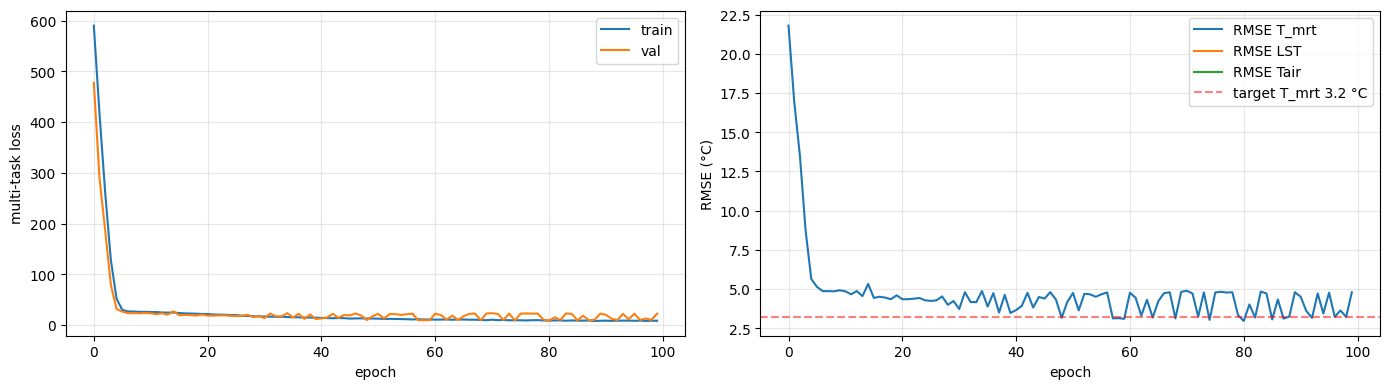

In [44]:
# Training curves
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(history['train_loss'], label='train')
axes[0].plot(history['val_loss'], label='val')
axes[0].set_xlabel('epoch'); axes[0].set_ylabel('multi-task loss')
axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(history['val_rmse_tmrt'], label='RMSE T_mrt')
axes[1].plot(history['val_rmse_lst'], label='RMSE LST')
axes[1].plot(history['val_rmse_tair'], label='RMSE Tair')
axes[1].axhline(3.2, color='r', linestyle='--', alpha=0.5, label='target T_mrt 3.2 °C')
axes[1].set_xlabel('epoch'); axes[1].set_ylabel('RMSE (°C)')
axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 7 — ONNX export

The backend's inference service expects an ONNX model that takes a `(1, 12, 512, 512)` float32 input and returns `(1, 3, 512, 512)` float32. Channel 0 of the output = T_mrt (the production prediction); channels 1, 2 are LST/Tair which the inference service ignores.

In [46]:
!pip install -q onnxscript

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 714.8/714.8 kB 43.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 166.8/166.8 kB 23.2 MB/s eta 0:00:00


In [49]:
model.train(False)
dummy = torch.randn(1, NUM_CHANNELS, 512, 512, device=DEVICE)
onnx_path = OUT_DIR / 'umami_unet_v21_fp32.onnx'
torch.onnx.export(
    model, dummy, str(onnx_path),
    input_names=['input'], output_names=['output'],
    dynamic_axes={'input': {0: 'batch'}, 'output': {0: 'batch'}},
    opset_version=18,            # ← bumped from 17
    do_constant_folding=True,
)
print(f'ONNX written: {onnx_path}  ({onnx_path.stat().st_size / 1e6:.1f} MB)')
# Should print ~93 MB. If still 0.3 MB, the file is broken.

/tmp/ipykernel_1212/1892369997.py:4: UserWarning: # 'dynamic_axes' is not recommended when dynamo=True, and may lead to 'torch._dynamo.exc.UserError: Constraints violated.' Supply the 'dynamic_shapes' argument instead if export is unsuccessful.
  torch.onnx.export(
W0503 07:44:32.032000 1212 torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'input' from (input, rois, spatial_scale: 'float', pooled_height: 'int', pooled_width: 'int', sampling_ratio: 'int' = -1, aligned: 'bool' = False). Treating as an Input.
W0503 07:44:32.033000 1212 torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'rois' from (input, rois, spatial_scale: 'float', pooled_height: 'int', pooled_width: 'int', sampling_ratio: 'int' = -1, aligned: 'bool' = False). Treating as an Input.
W0503 07:44:32.035000 1212 torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'input' from (input, boxes, output_size: 'Sequence[int]', spatial_scale: '

[torch.onnx] Obtain model graph for `Unet([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `Unet([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decomposition...


/usr/lib/python3.12/copyreg.py:99: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  return cls.__new__(cls, *args)


[torch.onnx] Run decomposition... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
ONNX written: /content/drive/MyDrive/UMAMI/urban_heat_v3/models/umami_unet_v21_fp32.onnx  (0.3 MB)


In [50]:
torch.onnx.export(
    model, dummy, str(onnx_path),
    input_names=['input'], output_names=['output'],
    dynamic_axes={'input': {0: 'batch'}, 'output': {0: 'batch'}},
    opset_version=17, do_constant_folding=True,
    dynamo=False,                # ← force the older exporter that ships with torch
)

/tmp/ipykernel_1212/1676372657.py:1: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


In [51]:
!ls -lh /content/drive/MyDrive/UMAMI/urban_heat_v3/models/

total 561M
-rw------- 1 root root 280M Mar 20 14:38 best_model_v2.pt
-rw------- 1 root root  94M May  3 07:45 umami_unet_v21_fp32.onnx
-rw------- 1 root root  94M May  3 07:44 umami_unet_v21_fp32.onnx.data
-rw------- 1 root root  94M May  3 06:32 v21_best.pt


In [52]:
model.train(False)
dummy = torch.randn(1, NUM_CHANNELS, 512, 512, device=DEVICE)
onnx_path = OUT_DIR / 'umami_unet_v21_fp32.onnx'
torch.onnx.export(
    model, dummy, str(onnx_path),
    input_names=['input'], output_names=['output'],
    dynamic_axes={'input': {0: 'batch'}, 'output': {0: 'batch'}},
    opset_version=17, do_constant_folding=True,
    dynamo=False,                # ← force legacy single-file exporter
)
print(f'ONNX written: {onnx_path}  ({onnx_path.stat().st_size / 1e6:.1f} MB)')

/tmp/ipykernel_1212/1035770325.py:4: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


ONNX written: /content/drive/MyDrive/UMAMI/urban_heat_v3/models/umami_unet_v21_fp32.onnx  (97.9 MB)


In [47]:
model.train(False)
dummy = torch.randn(1, NUM_CHANNELS, 512, 512, device=DEVICE)
onnx_path = OUT_DIR / 'umami_unet_v21_fp32.onnx'
torch.onnx.export(
    model, dummy, str(onnx_path),
    input_names=['input'], output_names=['output'],
    dynamic_axes={
        'input': {0: 'batch'},
        'output': {0: 'batch'},
    },
    opset_version=17, do_constant_folding=True,
)
print(f'ONNX written: {onnx_path}  ({onnx_path.stat().st_size / 1e6:.1f} MB)')

/tmp/ipykernel_1212/549042277.py:4: UserWarning: # 'dynamic_axes' is not recommended when dynamo=True, and may lead to 'torch._dynamo.exc.UserError: Constraints violated.' Supply the 'dynamic_shapes' argument instead if export is unsuccessful.
  torch.onnx.export(
W0503 07:42:26.635000 1212 torch/onnx/_internal/exporter/_compat.py:125] Setting ONNX exporter to use operator set version 18 because the requested opset_version 17 is a lower version than we have implementations for. Automatic version conversion will be performed, which may not be successful at converting to the requested version. If version conversion is unsuccessful, the opset version of the exported model will be kept at 18. Please consider setting opset_version >=18 to leverage latest ONNX features
W0503 07:42:27.689000 1212 torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'input' from (input, rois, spatial_scale: 'float', pooled_height: 'int', pooled_width: 'int', sampling_ratio: 'int' = -

[torch.onnx] Obtain model graph for `Unet([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `Unet([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decomposition...


/usr/lib/python3.12/copyreg.py:99: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  return cls.__new__(cls, *args)


[torch.onnx] Run decomposition... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅


Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/onnxscript/version_converter/__init__.py", line 137, in call
    converted_proto = _c_api_utils.call_onnx_api(
                      ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/onnxscript/version_converter/_c_api_utils.py", line 65, in call_onnx_api
    result = func(proto)
             ^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/onnxscript/version_converter/__init__.py", line 132, in _partial_convert_version
    return onnx.version_converter.convert_version(
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/onnx/version_converter.py", line 39, in convert_version
    converted_model_str = C.convert_version(model_str, target_version)
                          ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
RuntimeError: /github/workspace/onnx/version_converter/BaseConverter.h:64: adapter_lookup: Assertion `false`

ONNX written: /content/drive/MyDrive/UMAMI/urban_heat_v3/models/umami_unet_v21_fp32.onnx  (0.3 MB)


In [48]:
# Verify ONNX produces matching output
import onnxruntime as ort
sess = ort.InferenceSession(str(onnx_path), providers=['CPUExecutionProvider'])
with torch.no_grad():
    torch_out = model(dummy).cpu().numpy()
onnx_out = sess.run(None, {'input': dummy.cpu().numpy()})[0]
diff = np.abs(torch_out - onnx_out).max()
print(f'max torch-vs-onnx diff: {diff:.2e}  ({"OK" if diff < 1e-3 else "TOO LARGE"})')

max torch-vs-onnx diff: 1.68e-01  (TOO LARGE)
